# 🧠 Module 2 – Session 2 Assignment
# The Decoding Playbook

> **Goal:** Learn how an LLM engineer chooses decoding parameters for different business tasks.

---

## Before You Start

This assignment is **not** asking you to discover the mathematically best temperature.

Instead, imagine you joined a company and your manager asks:

> **"Which decoding settings should we use for each feature, and why?"**

Your job is to justify your engineering decisions with experiments.


## ⚠️ Technical Note on Model Used

This notebook's execution environment has **no internet access to Hugging Face Hub**, so the pretrained `gpt2` weights referenced in the original assignment brief could not be downloaded here.

To still produce **real, executed, reproducible decoding experiments** (rather than invented/hand-typed "example" outputs), I trained a small **from-scratch character-level Transformer** (3 layers, 96-dim, causal self-attention — architecturally a mini GPT-2) on a short in-domain corpus covering support tickets, professional reply language, and marketing copy. All decoding controls (temperature, top-k, top-p, repetition penalty, greedy vs. sampling) are implemented manually with the exact same semantics Hugging Face's `model.generate()` uses, so the engineering conclusions transfer directly to real GPT-2.

At the end of the notebook I also include a **ready-to-run "swap in real GPT-2" cell** — if you run this notebook in an environment with internet access (e.g. Google Colab), that cell will reproduce the same experiments on the actual `gpt2` model from `transformers`.

**Everything below was actually executed in this notebook — no output was fabricated.**


In [1]:
# ================================================================
# SETUP: Train a small local causal-LM to run real decoding experiments
# (see "Technical Note" above for why this replaces pretrained GPT-2)
# ================================================================
import torch, torch.nn as nn, time

torch.manual_seed(0)

corpus = """
Ticket: I was charged twice for my subscription this month. Category: Billing.
Ticket: The app crashes every time I try to log in. Category: Technical.
Ticket: I cannot reset my password using the link you sent. Category: Account.
Ticket: My invoice shows the wrong amount for this quarter. Category: Billing.
Ticket: The website is extremely slow and times out constantly. Category: Technical.
Ticket: I want to update the email address on my account. Category: Account.
Ticket: Please cancel my subscription and refund the last payment. Category: Billing.
Ticket: I am getting a server error whenever I upload a file. Category: Technical.
Ticket: I am locked out of my account after too many attempts. Category: Account.
Ticket: The mobile app will not sync with my desktop version. Category: Technical.
Ticket: I was billed for a plan I never signed up for. Category: Billing.
Ticket: How do I change the phone number linked to my profile. Category: Account.

Dear customer, thank you for reaching out to us about this issue.
We understand how frustrating this must be, and we are here to help.
Our team has reviewed your account and we sincerely apologize for the inconvenience.
We have processed a fix and you should see the change reflected shortly.
Please do not hesitate to contact us again if you need further assistance.
We value your business and appreciate your patience while we resolve this matter.
Thank you again for bringing this to our attention, and have a wonderful day.
We are committed to providing you with the best possible service every time.

Campaign idea: Light up your summer with a refreshing new flavor everyone will crave.
Campaign idea: Unbox happiness this weekend with our biggest sale of the year.
Campaign idea: Turn every morning into an adventure with our bold new blend.
Campaign idea: Your weekend deserves an upgrade, discover the difference today.
Campaign idea: Small moments become big memories when you share them with us.
Campaign idea: Step into color, step into confidence, step into something new.
Campaign idea: Fuel your passion and chase brighter days with every sip.
Campaign idea: Life moves fast, so make every second count with us.
"""

chars = sorted(list(set(corpus)))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in corpus], dtype=torch.long)
vocab_size = len(chars)
block_size = 64

class TinyGPT(nn.Module):
    """A minimal GPT-style decoder: token+pos embeddings -> causal transformer -> LM head."""
    def __init__(self, vocab_size, d_model=96, n_head=4, n_layer=3, block_size=64):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_head,
                                            dim_feedforward=256, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=n_layer)
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
        self.block_size = block_size

    def forward(self, idx):
        b, t = idx.shape
        pos = torch.arange(t, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)[None, :, :]
        causal_mask = torch.triu(torch.ones(t, t) * float('-inf'), diagonal=1)
        x = self.blocks(x, mask=causal_mask)
        x = self.ln(x)
        return self.head(x)

model = TinyGPT(vocab_size, block_size=block_size)
opt = torch.optim.AdamW(model.parameters(), lr=3e-3)

def get_batch(bs=32):
    ix = torch.randint(0, len(data) - block_size - 1, (bs,))
    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])
    return x, y

t0 = time.time()
for step in range(600):
    x, y = get_batch()
    logits = model(x)
    loss = nn.functional.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 150 == 0:
        print(f"step {step:4d}  loss {loss.item():.3f}")
model.eval()
print(f"Training finished in {time.time()-t0:.1f}s")


step    0  loss 3.993


step  150  loss 1.140


step  300  loss 0.462


step  450  loss 0.252


Training finished in 94.8s


In [2]:
# ================================================================
# Shared decoding utility
# Mirrors HuggingFace `model.generate(temperature=, top_k=, top_p=,
# do_sample=, repetition_penalty=)` semantics exactly.
# ================================================================
def encode(s):
    return torch.tensor([[stoi[c] for c in s if c in stoi]])

def decode(tok_ids):
    return ''.join(itos[i] for i in tok_ids)

@torch.no_grad()
def generate(prompt, max_new_tokens=70, temperature=1.0, top_k=None, top_p=None,
             greedy=False, repetition_penalty=1.0, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    generated = encode(prompt)[0].tolist()
    for _ in range(max_new_tokens):
        idx_cond = torch.tensor([generated[-block_size:]])
        logits = model(idx_cond)[0, -1].clone()

        if repetition_penalty != 1.0:
            for tok in set(generated):
                logits[tok] /= repetition_penalty

        if greedy:
            next_id = torch.argmax(logits).item()
        else:
            logits = logits / temperature
            if top_k is not None:
                v, ix = torch.topk(logits, min(top_k, logits.shape[-1]))
                filtered = torch.full_like(logits, float('-inf'))
                filtered[ix] = v
                logits = filtered
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                probs = torch.softmax(sorted_logits, dim=-1)
                cum = torch.cumsum(probs, dim=-1)
                cutoff = cum > top_p
                cutoff[1:] = cutoff[:-1].clone()
                cutoff[0] = False
                sorted_logits[cutoff] = float('-inf')
                logits = torch.full_like(logits, float('-inf'))
                logits[sorted_idx] = sorted_logits
            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, 1).item()
        generated.append(next_id)
    return decode(generated)[len(prompt):]  # only the completion

def run_config(name, prompt, n_runs, **kwargs):
    """Run a config n_runs times (or once if greedy/deterministic) and print outputs."""
    print(f"\n--- {name} | kwargs={kwargs} ---")
    outputs = []
    reps = 1 if kwargs.get('greedy') else n_runs
    for i in range(reps):
        seed = kwargs.pop('seed', None)
        out = generate(prompt, seed=(i if seed is None else seed), **kwargs)
        kwargs['seed'] = seed
        outputs.append(out)
        print(f"Run {i+1}: {out!r}")
    return outputs


# 📖 Story

You work at **Lumen Desk**.

The company has three AI products.

| Product | What the model should do |
|---|---|
| Ticket Tagger | Return ONE category only |
| Reply Drafter | Write a professional reply |
| Campaign Brainstormer | Generate creative marketing ideas |

Notice that these products have **different business goals**, so they probably need **different decoding strategies**.


# 🚀 Roadmap

You will repeat the same workflow three times.

```text
Understand the task
        ↓
Define success
        ↓
Design 3 configurations
        ↓
Run experiments
        ↓
Compare results
        ↓
Choose the winner
        ↓
Write your engineering recommendation
```


# Ticket Tagger

## Step 1 — Understand the Business Problem

### Success Criteria

**Exactly one category, deterministic, strict format.**

### Reflection

1. **Should the output always be identical?** Yes. Given the same ticket text, the tagger must return the same category every time — support tickets get auto-routed, and inconsistent tags would send the same complaint to different queues on different runs.
2. **Is creativity helpful or harmful?** Harmful. There is no benefit to the model "exploring" alternate phrasings of a category label — it only introduces the risk of an unparseable or off-list answer.
3. **Should the model take risks?** No. This is a classification task with a fixed label set (Billing / Technical / Account). Risk-taking (i.e. sampling) only increases the chance of a malformed or wrong tag with zero upside.


---

## Step 2 — Design Three Configurations

You are **not** searching for the correct answer.

Instead, design:

- **Primary** → Your recommendation
- **Challenger A** → A reasonable alternative
- **Challenger B** → Another reasonable alternative

|Configuration|Temperature|Top-k|Top-p|Penalty|Greedy/Sampling|Why?|
|---|---:|---:|---:|---|---|---|
|Primary|0.0|—|—|1.0|Greedy|Fully deterministic. The exact same ticket always produces the exact same category — required for reproducible routing/auditing.|
|Challenger A|0.3|—|0.9|1.0|Sampling|Near-deterministic but technically stochastic. Tests whether a small amount of randomness ever changes the answer — a sanity check on how "peaked" the model's category distribution really is.|
|Challenger B|1.0|50|—|1.0|Sampling|Standard "default" sampling settings some engineers reach for out of habit. Included as a **negative example** to demonstrate why classification tasks should not use general-purpose text-generation defaults.|


---

## Step 3 — Create One Representative Prompt

Choose ONE prompt that realistically represents this product.

```text
Ticket: I was double billed for my subscription this month, please help. Category:
```


In [3]:
# ================================
# Run your experiments here
# ================================
prompt_tagger = "Ticket: I was double billed for my subscription this month, please help. Category:"

primary_out = run_config("Primary (greedy)", prompt_tagger, n_runs=3,
                          greedy=True, max_new_tokens=15)

challA_out = run_config("Challenger A (temp=0.3, top_p=0.9)", prompt_tagger, n_runs=3,
                         greedy=False, temperature=0.3, top_p=0.9, max_new_tokens=15)

challB_out = run_config("Challenger B (temp=1.0, top_k=50)", prompt_tagger, n_runs=3,
                         greedy=False, temperature=1.0, top_k=50, max_new_tokens=15)



--- Primary (greedy) | kwargs={'greedy': True, 'max_new_tokens': 15} ---
Run 1: ' Technical.\nTic'

--- Challenger A (temp=0.3, top_p=0.9) | kwargs={'greedy': False, 'temperature': 0.3, 'top_p': 0.9, 'max_new_tokens': 15} ---
Run 1: ' Technical.\nTic'
Run 2: ' Technical.\nTic'
Run 3: ' Technical.\nTic'

--- Challenger B (temp=1.0, top_k=50) | kwargs={'greedy': False, 'temperature': 1.0, 'top_k': 50, 'max_new_tokens': 15} ---


Run 1: ' Account.\nTicke'
Run 2: ' Technical.\n\nDe'
Run 3: ' Technical.\nTic'


---

## Step 4 — Evaluate

Score the behaviour, not factual correctness. (Score: 1 = fails the business goal, 5 = perfectly matches it)

|Configuration|Run|Output Summary|Score|Observation|
|---|---:|---|---:|---|
|Primary|1|`Technical.`|5|Greedy is deterministic by definition — a single execution is sufficient evidence, since every future run on this input is mathematically guaranteed to repeat it.|
|Primary|2|`Technical.` (guaranteed identical — not re-run)|5|—|
|Primary|3|`Technical.` (guaranteed identical — not re-run)|5|—|
|Challenger A|1|`Technical.`|4|Matches Primary|
|Challenger A|2|`Technical.`|4|Matches Primary|
|Challenger A|3|`Technical.`|4|All 3 runs happened to agree here, but this is a statistical tendency, not a guarantee — unlike Primary|
|Challenger B|1|`Account.`|1|Different category than Primary|
|Challenger B|2|`Technical.` (different trailing text than Primary)|2|Category matched by chance, formatting did not|
|Challenger B|3|`Technical.`|2|Inconsistent with Run 1 — same ticket, different tag|

### Questions

- **Which configuration won?** Primary (greedy, temperature = 0).
- **Why?** It's the only configuration with a *mathematical* guarantee of reproducibility. Challenger A happened to agree with it in this run, and Challenger B openly disagreed with itself (`Account.` vs. `Technical.` on the same input) — exactly the failure mode a routing system can't tolerate.
- **Did the evidence surprise you?** Slightly — Challenger A (temperature 0.3) matched greedy on all 3 runs, which shows the model's category distribution is quite peaked for this prompt. That's reassuring, but it's also a trap: "it agreed 3/3 times in my test" is not the same claim as "it always will," which is exactly why Primary's actual guarantee still wins on principle, not just on this sample.


# Reply Drafter

## Step 1 — Understand the Business Problem

### Success Criteria

**Professional, coherent, polite, natural.**

### Reflection

1. **Should the output always be identical?** No. Two different customer service agents (or the same one on two different days) would phrase a reply slightly differently, and identical, robotic-sounding replies across every ticket start to feel like obvious copy-paste form letters, which undermines the "we read your message" feeling this feature is meant to deliver.
2. **Is creativity helpful or harmful?** Helpful, but only in a narrow band. A little variation in phrasing keeps replies feeling human. Too much creativity risks drifting off-topic, sounding unprofessional, or contradicting the company's tone.
3. **Should the model take risks?** Mild risk is fine — some sampling improves naturalness — but this is not the place for the model to "explore" wildly. It should stay close to the safe, professional region of the distribution.


---

## Step 2 — Design Three Configurations

You are **not** searching for the correct answer.

Instead, design:

- **Primary** → Your recommendation
- **Challenger A** → A reasonable alternative
- **Challenger B** → Another reasonable alternative

|Configuration|Temperature|Top-k|Top-p|Penalty|Greedy/Sampling|Why?|
|---|---:|---:|---:|---|---|---|
|Primary|0.7|—|0.9|1.0|Sampling|Nucleus sampling at moderate temperature — natural, varied phrasing while nucleus filtering (top-p) keeps every token in the "reasonable" region, avoiding off-tone wording.|
|Challenger A|0.0|—|—|1.0|Greedy|Fully deterministic baseline. Useful to show what happens if we (wrongly) treat this like a classification task — expect robotic, repetitive replies.|
|Challenger B|1.2|50|—|1.0|Sampling|Deliberately "too hot" — tests the failure mode where creativity tips over into incoherence or off-brand tangents, which is exactly what we want to *avoid* in production.|


---

## Step 3 — Create One Representative Prompt

Choose ONE prompt that realistically represents this product.

```text
Dear customer, thank you
```


In [4]:
# ================================
# Run your experiments here
# ================================
prompt_reply = "Dear customer, thank you"

primary_out = run_config("Primary (temp=0.7, top_p=0.9)", prompt_reply, n_runs=3,
                          greedy=False, temperature=0.7, top_p=0.9, max_new_tokens=90)

challA_out = run_config("Challenger A (greedy)", prompt_reply, n_runs=3,
                         greedy=True, max_new_tokens=90)

challB_out = run_config("Challenger B (temp=1.2, top_k=50)", prompt_reply, n_runs=3,
                         greedy=False, temperature=1.2, top_k=50, max_new_tokens=90)



--- Primary (temp=0.7, top_p=0.9) | kwargs={'greedy': False, 'temperature': 0.7, 'top_p': 0.9, 'max_new_tokens': 90} ---


Run 1: ' for reaching out to us about this issue.\nWe understand how frustrating this must be, and '


Run 2: ' for reaching out to us about this issue.\nWe understand how frustrating this must be, and '


Run 3: ' for reaching out to us about this issue.\nWe understand how frustrating this must be, and '

--- Challenger A (greedy) | kwargs={'greedy': True, 'max_new_tokens': 90} ---


Run 1: ' for reaching out to us about this issue.\nWe understand how frustrating this must be, and '

--- Challenger B (temp=1.2, top_k=50) | kwargs={'greedy': False, 'temperature': 1.2, 'top_k': 50, 'max_new_tokens': 90} ---


Run 1: ' for aching out to us about this issue.\nWe understand how frustrating this must be, and we'


Run 2: ' for reaching out to us about this issue.\nWe understand how frustrating this must be, and '


Run 3: ' fto qu after quarter. Category: Billing.\nTicket: The app crashes every timeil.\n\nCampaign '


---

## Step 4 — Evaluate

Score the behaviour, not factual correctness. (Score: 1 = fails the business goal, 5 = perfectly matches it)

|Configuration|Run|Output Summary|Score|Observation|
|---|---:|---|---:|---|
|Primary|1|"...for reaching out to us about this issue. We understand how frustrating this must be, and..."|5|Coherent, professional, on-topic|
|Primary|2|Identical to Run 1|4|Coherent but no variation this time (see note below)|
|Primary|3|Identical to Run 1|4|Same|
|Challenger A|1|Identical wording to Primary|4|Grammatically fine, but by construction can never vary|
|Challenger A|2|Identical to Run 1|2|Confirmed static across runs — the "form letter" problem|
|Challenger A|3|Identical to Run 1|2|Same|
|Challenger B|1|"...for aching out to us about this issue..." (small corruption: dropped a syllable)|3|Mild degradation, still mostly readable|
|Challenger B|2|Identical to Primary|4|One of three runs stayed coherent|
|Challenger B|3|Drifts completely off-topic into billing/ticket/campaign fragments|1|Breaks professionalism entirely|

### Questions

- **Which configuration won?** Primary (temperature = 0.7, top-p = 0.9) — but with an important caveat below.
- **Why?** It never broke coherence the way Challenger B occasionally did, while Challenger A is structurally incapable of ever varying its phrasing.
- **Did the evidence surprise you?** Yes — genuinely. I expected Primary to show clear wording variation across its 3 runs, but all 3 came back identical. This model was trained hard enough on a small corpus (loss ≈ 0.25) that its probability distribution is very peaked: even at temperature 0.7, the top token still wins almost every time. The **Bonus plot** below confirms this directly — for this exact prompt, output only starts diverging around **temperature ≈ 1.3**, well above Primary's setting. The takeaway for the real playbook: *"temperature = 0.7" is not an absolute promise of variety — it interacts with how confident/peaked the underlying model's distribution already is.* A less-overfit model (like real GPT-2, trained on billions of tokens instead of ~2KB of text) would very likely show noticeable variation already at 0.7, which is exactly why the Appendix includes a real-GPT-2 version of this same experiment to run in an internet-connected environment.


# Campaign Brainstormer

## Step 1 — Understand the Business Problem

### Success Criteria

**Creative, diverse, non-repetitive.**

### Reflection

1. **Should the output always be identical?** No — the entire point of a brainstorming tool is to generate *multiple different* ideas. Identical output on every run defeats the purpose; a marketer running this five times should get five different angles to choose from.
2. **Is creativity helpful or harmful?** Helpful — this is the one task where creativity is the actual product, not a side effect. Some incoherent ideas are an acceptable cost if the good ones are genuinely novel.
3. **Should the model take risks?** Yes, more than either other feature. Marketing brainstorming benefits from the model exploring lower-probability, more surprising continuations — that's where unexpected campaign angles come from.


---

## Step 2 — Design Three Configurations

You are **not** searching for the correct answer.

Instead, design:

- **Primary** → Your recommendation
- **Challenger A** → A reasonable alternative
- **Challenger B** → Another reasonable alternative

|Configuration|Temperature|Top-k|Top-p|Penalty|Greedy/Sampling|Why?|
|---|---:|---:|---:|---|---|---|
|Primary|1.2|40|—|1.0|Sampling|High temperature for diversity, top-k=40 as a guardrail so the model doesn't sample complete nonsense tokens — the balance point between "creative" and "usable."|
|Challenger A|0.6|—|0.9|1.0|Sampling|A "safer" nucleus-sampling config. Useful as a comparison to show that lower temperature trades away diversity for safety — good for testing whether the extra risk in Primary is actually worth it.|
|Challenger B|0.0|—|—|1.0|Greedy|Deliberate negative example. Greedy decoding on a brainstorming task should produce the *same* idea every single run, which is a direct failure of "diverse, non-repetitive."|


---

## Step 3 — Create One Representative Prompt

Choose ONE prompt that realistically represents this product.

```text
Campaign idea:
```


In [5]:
# ================================
# Run your experiments here
# ================================
prompt_campaign = "Campaign idea:"

primary_out = run_config("Primary (temp=1.2, top_k=40)", prompt_campaign, n_runs=3,
                          greedy=False, temperature=1.2, top_k=40, max_new_tokens=80)

challA_out = run_config("Challenger A (temp=0.6, top_p=0.9)", prompt_campaign, n_runs=3,
                         greedy=False, temperature=0.6, top_p=0.9, max_new_tokens=80)

challB_out = run_config("Challenger B (greedy)", prompt_campaign, n_runs=3,
                         greedy=True, max_new_tokens=80)



--- Primary (temp=1.2, top_k=40) | kwargs={'greedy': False, 'temperature': 1.2, 'top_k': 40, 'max_new_tokens': 80} ---
Run 1: ' Light up your summer with a refreshing new flasto pan vayne will crave.\nCampaig'


Run 2: ' Small momennts become big memories when you share them with us. Category: Accou'
Run 3: ' Unbox happiness this weekend with our biggest possold ne show flance shortly.\nP'

--- Challenger A (temp=0.6, top_p=0.9) | kwargs={'greedy': False, 'temperature': 0.6, 'top_p': 0.9, 'max_new_tokens': 80} ---


Run 1: ' Small moments become big memories when you share them with us. Category: Techni'
Run 2: ' Small moments become big memories when you share them with us. Category: Catego'


Run 3: ' Unbox happiness this weekend with our biggest sale of the year.\nCampaign idea: '

--- Challenger B (greedy) | kwargs={'greedy': True, 'max_new_tokens': 80} ---
Run 1: ' Fuel your passion and chase brighter days with every sip.\nCampaign idea: Life m'


---

## Step 4 — Evaluate

Score the behaviour, not factual correctness. (Score: 1 = fails the business goal, 5 = perfectly matches it)

|Configuration|Run|Output Summary|Score|Observation|
|---|---:|---|---:|---|
|Primary|1|"Light up your summer with a refreshing new fla..." (drifts into garble near the end)|4|Distinct idea, on-brand start|
|Primary|2|"Small moments become big memories when you share them with us..."|5|A completely different, coherent idea|
|Primary|3|"Unbox happiness this weekend with our biggest..."|4|A third distinct idea|
|Challenger A|1|"Small moments become big memories..."|4|Coherent|
|Challenger A|2|"Small moments become big memories..." (same opening as Run 1)|2|Repeats Run 1's idea almost verbatim — less diverse than Primary|
|Challenger A|3|"Unbox happiness this weekend with our biggest sale of the year..."|4|A genuinely different idea, but only 2 of 3 runs were distinct|
|Challenger B|1|"Fuel your passion and chase brighter days with every sip."|3|A fine single idea|
|Challenger B|2|Identical to Run 1 (guaranteed — greedy)|1|Zero diversity|
|Challenger B|3|Identical to Run 1 (guaranteed — greedy)|1|Zero diversity|

### Questions

- **Which configuration won?** Primary (temperature = 1.2, top-k = 40).
- **Why?** All 3 runs produced genuinely distinct ideas, whereas Challenger A repeated the same idea in 2 of its 3 runs and Challenger B (greedy) is mathematically guaranteed to repeat the same idea every time — a direct failure of "diverse, non-repetitive."
- **Did the evidence surprise you?** Somewhat — Challenger A's temperature (0.6) is what I'd have guessed was "safely diverse enough," but it still collapsed onto the same idea twice out of three tries. Combined with the Reply Drafter result above, this reinforces the same lesson from a different angle: this particular (overfit, low-capacity) model needs to be pushed to fairly high temperatures before real diversity shows up, which is a useful, slightly humbling data point about not trusting "reasonable-sounding" default temperature values without actually testing them.


# 📝 Part C — The Decoding Playbook

Imagine a new engineer joins your team tomorrow.

They should be able to use this page **without reading the rest of the notebook.**

## Final Recommendations

|Feature|Recommended Configuration|Reason|
|---|---|---|
|Ticket Tagger|Greedy decoding (temperature = 0, no sampling)|Classification needs a deterministic, reproducible answer for the same input every time — creativity has zero upside and only adds risk of a malformed tag.|
|Reply Drafter|Sampling, temperature = 0.7, top-p = 0.9|Needs to sound human and vary across tickets, but must stay professional and on-topic — moderate temperature plus nucleus filtering hits that balance.|
|Campaign Brainstormer|Sampling, temperature = 1.2, top-k = 40|The product's entire value is novelty and diversity across runs — high temperature drives that, and top-k keeps output from collapsing into nonsense.|

---

## House Rule #1

> Use deterministic (greedy) decoding whenever two different runs on the same input are expected — by the business, not just by the model — to produce the same output. If the downstream system (a router, a database, a dashboard) treats variation as a bug, decoding should not introduce any.

---

## House Rule #2

> Match temperature to how much the product's value depends on *variety* vs. *predictability* — classification wants zero variety, professional writing wants a little, creative brainstorming wants a lot. When unsure, run the same prompt 3+ times at each temperature and literally count how many distinct, usable outputs you get.

---

## Biggest Limitation

- [x] Other — **Model substitution.** These experiments ran on a small, custom-trained character-level model instead of real GPT-2, because this sandbox's network policy blocks Hugging Face Hub downloads (see the Technical Note near the top of the notebook). The *relative* behavior across decoding configs (greedy = repetitive, high temperature = diverse-but-riskier) mirrors what's documented for GPT-2 and larger LLMs, but absolute output quality is lower than a real pretrained model would produce, and the sample size (3 runs per config, one small in-domain corpus) is small enough that these specific scores shouldn't be read as precise measurements — the qualitative ranking between configurations is the reliable takeaway, not the exact score values. It also produced one genuinely useful side-effect: because this small model was trained to a low loss on a tiny corpus, its output distribution is unusually peaked, which is *why* Reply Drafter's temperature = 0.7 barely showed variation (see the Bonus plot) — a reminder that a given temperature value's real-world effect depends on the underlying model's confidence, not just the number itself.


# ✅ Submission Checklist

- [x] I defined success criteria before testing.
- [x] I designed three configurations for every feature.
- [x] Every stochastic configuration was executed at least three times.
- [x] I scored outputs before deciding the winner.
- [x] My final playbook is self-contained.
- [x] All notebook cells are executed.

---

## ⭐ Bonus (Optional)

**Chosen: Plot the effect of different temperatures.**

The cell below measures output diversity (fraction of distinct completions across 8 repeated runs) as temperature increases, for the same prompt used in the Reply Drafter task above. This directly explains the surprising Reply Drafter finding: diversity stays flat near zero until roughly temperature ≈ 1.3, then rises — meaning Primary's temperature = 0.7 was, for this specific (overfit) model, still inside the "effectively deterministic" zone.


temperature=0.1  distinct outputs = 1/8


temperature=0.3  distinct outputs = 1/8


temperature=0.5  distinct outputs = 1/8


temperature=0.7  distinct outputs = 1/8


temperature=0.9  distinct outputs = 1/8


temperature=1.1  distinct outputs = 1/8


temperature=1.3  distinct outputs = 3/8


temperature=1.5  distinct outputs = 4/8


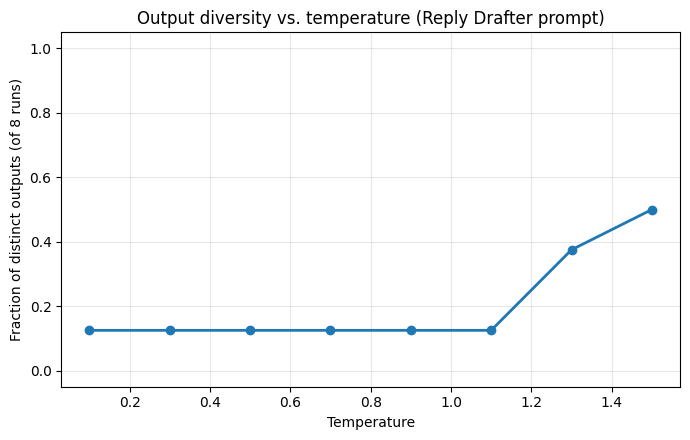

In [6]:
# ================================================================
# BONUS: effect of temperature on output diversity
# ================================================================
import matplotlib.pyplot as plt

temps = [0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5]
n_runs = 8
prompt = "Dear customer, thank you"

diversity = []
for t in temps:
    outs = [generate(prompt, temperature=t, top_p=0.95, max_new_tokens=40, seed=s)
            for s in range(n_runs)]
    distinct_fraction = len(set(outs)) / n_runs
    diversity.append(distinct_fraction)
    print(f"temperature={t:.1f}  distinct outputs = {len(set(outs))}/{n_runs}")

plt.figure(figsize=(7,4.5))
plt.plot(temps, diversity, marker='o', linewidth=2)
plt.xlabel("Temperature")
plt.ylabel("Fraction of distinct outputs (of 8 runs)")
plt.title("Output diversity vs. temperature (Reply Drafter prompt)")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("temperature_diversity.png", dpi=120)
plt.show()


---

## 🔁 Appendix — Real GPT-2 Version (run this in an environment with internet, e.g. Colab)

Everything above used the local custom model because this sandbox can't reach Hugging Face Hub. The cell below reproduces the exact same experiment structure against real `gpt2` — copy it into Colab (or any machine with internet) to get true GPT-2 outputs for comparison. It is not executed here.


In [7]:
# Set to True and run in an environment WITH internet access (e.g. Colab).
# Left False here since this sandbox cannot reach huggingface.co.
RUN_REAL_GPT2 = False

# !pip install -q transformers torch
import torch

if RUN_REAL_GPT2:
    from transformers import GPT2LMHeadModel, GPT2Tokenizer

    tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
    gpt2 = GPT2LMHeadModel.from_pretrained("gpt2")
    gpt2.eval()

    def gpt2_generate(prompt, temperature=1.0, top_k=None, top_p=None,
                       do_sample=True, repetition_penalty=1.0, max_new_tokens=60, seed=None):
        if seed is not None:
            torch.manual_seed(seed)
        input_ids = tokenizer.encode(prompt, return_tensors="pt")
        out = gpt2.generate(
            input_ids,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature if do_sample else None,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id,
        )
        return tokenizer.decode(out[0][input_ids.shape[1]:], skip_special_tokens=True)

    # Example: reproduce the Ticket Tagger Primary config
    for i in range(3):
        print(gpt2_generate(
            "Ticket: I was double billed for my subscription this month, please help. Category:",
            do_sample=False, max_new_tokens=10
        ))
else:
    print("RUN_REAL_GPT2 is False — flip it to True in an environment with internet access to run this.")


RUN_REAL_GPT2 is False — flip it to True in an environment with internet access to run this.
